<div dir="rtl" align="right">

# הגרלת מספרים במחשב: מפסאודו־אקראיות להתפלגויות

### במחברת זו נלמד כיצד מחשב מייצר מספרים שנראים אקראיים, מה פירוש המושג פסאודו־אקראי, ומה התפקיד של seed.

### לאחר מכן נראה כיצד מספרים אחידים בין 0 ל־1 משמשים כחומר גלם ליצירת משתנים מקריים מהתפלגויות שונות.

### לבסוף ניישם את הרעיונות באמצעות NumPy ונשווה בין התיאוריה לבין תוצאות סימולציה.

</div>

<div dir="rtl" align="right">

# 1. למה מחשב לא באמת מגריל?

### מחשב רגיל הוא מערכת דטרמיניסטית, כלומר אם ניתן לו בדיוק את אותו מצב התחלתי ואת אותן הוראות, הוא יבצע בדיוק את אותן פעולות.

### לכן ברוב השימושים בתכנות המחשב אינו מייצר אקראיות אמיתית, אלא מפעיל אלגוריתם שמייצר סדרה שנראית אקראית.

### סדרה כזאת נקראת סדרה פסאודו־אקראית, והאלגוריתם שמייצר אותה נקרא Pseudo-Random Number Generator או בקיצור PRNG.

</div>

<div dir="rtl" align="right">

# 2. דוגמה פשוטה ל־PRNG

### נבחן מחולל פשוט מהצורה $X_{n+1}=(5X_n+3)\mod 16$.

### הערך הראשון $X_0$ נקרא seed והוא קובע לחלוטין את כל הסדרה שתתקבל לאחר מכן.

### המחולל הבא אינו מחולל טוב לשימוש אמיתי, אבל הוא מצוין לצורך הבנת הרעיון.

</div>

In [1]:
def simple_prng(seed, n=12):
    x = seed
    values = []
    for _ in range(n):
        x = (5 * x + 3) % 16
        values.append(x)
    return values

print("seed = 7 :", simple_prng(7))
print("seed = 7 :", simple_prng(7))
print("seed = 8 :", simple_prng(8))


seed = 7 : [6, 1, 8, 11, 10, 5, 12, 15, 14, 9, 0, 3]
seed = 7 : [6, 1, 8, 11, 10, 5, 12, 15, 14, 9, 0, 3]
seed = 8 : [11, 10, 5, 12, 15, 14, 9, 0, 3, 2, 13, 4]


<div dir="rtl" align="right">

# 3. למה seed חשוב?

### אם משתמשים באותו seed ובאותו מחולל, נקבל בדיוק את אותה סדרת מספרים.

### תכונה זו חשובה מאוד במחקר ובסימולציה משום שהיא מאפשרת לשחזר ניסוי בדיוק.

### לעומת זאת, אם נשנה את ה־seed נקבל בדרך כלל סדרה שונה.

</div>

In [2]:
import numpy as np


rng1 = np.random.default_rng(seed=123)
rng2 = np.random.default_rng(seed=123)
rng3 = np.random.default_rng(seed=999)

print("Generator 1:", rng1.random(5))
print("Generator 2:", rng2.random(5))
print("Generator 3:", rng3.random(5))


Generator 1: [0.68235186 0.05382102 0.22035987 0.18437181 0.1759059 ]
Generator 2: [0.68235186 0.05382102 0.22035987 0.18437181 0.1759059 ]
Generator 3: [0.77882502 0.17224863 0.71357279 0.75033508 0.17110908]


<div dir="rtl" align="right">

# 4. Uniform בין 0 ל־1

### אחד מאבני הבניין המרכזיות בסימולציה הוא משתנה מקרי $U\sim U(0,1)$.

### בהתפלגות אחידה כל קטע באורך נתון בתוך $[0,1]$ מקבל הסתברות השווה לאורך הקטע.

### לדוגמה, $P(U<0.2)=0.2$ וגם $P(0.4<U<0.7)=0.3$.

### ניתן לבדוק זאת אמפירית באמצעות מספר גדול של הגרלות.

</div>

In [3]:
import numpy as np

rng = np.random.default_rng(42)
u = rng.random(1_000_000)

print("P(U < 0.2) ≈", np.mean(u < 0.2))
print("P(0.4 < U < 0.7) ≈", np.mean((u > 0.4) & (u < 0.7)))
print("Sample mean ≈", np.mean(u))


P(U < 0.2) ≈ 0.199941
P(0.4 < U < 0.7) ≈ 0.300064
Sample mean ≈ 0.5000264761740889


<div dir="rtl" align="right">

# 5. היסטוגרמה של Uniform

### אם נגריל הרבה ערכים מ־$U(0,1)$ ונציג היסטוגרמה, נצפה לקבל בקירוב עמודות בגובה דומה לאורך כל התחום.

</div>

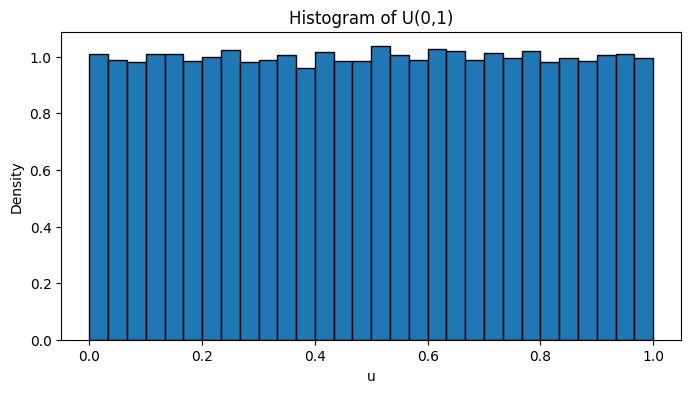

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(u[:100_000], bins=30, density=True, edgecolor="black")
plt.xlabel("u")
plt.ylabel("Density")
plt.title("Histogram of U(0,1)")
plt.show()


<div dir="rtl" align="right">

# 6. מ־Uniform ל־Bernoulli

### נניח שאנו רוצים משתנה מקרי $X$ שמקבל את הערך 1 בהסתברות $p$ ואת הערך 0 בהסתברות $1-p$.

### נגריל $U\sim U(0,1)$ ונגדיר $X=1$ אם $U<p$, ואחרת נגדיר $X=0$.

### הסיבה שהשיטה עובדת היא שהאורך של הקטע $[0,p)$ הוא בדיוק $p$.

</div>

In [5]:
rng = np.random.default_rng(123)
p = 0.3

u = rng.random(1_000_000)
x = (u < p).astype(int)

print("Estimated P(X=1):", x.mean())
print("Theoretical P(X=1):", p)


Estimated P(X=1): 0.299697
Theoretical P(X=1): 0.3


<div dir="rtl" align="right">

# 7. התפלגות דיסקרטית כללית

### נניח שאנו רוצים $P(X=10)=0.2$, $P(X=20)=0.5$ ו־$P(X=50)=0.3$.

### נחלק את הקטע $[0,1]$ לפי ההסתברויות המצטברות לקטעים $[0,0.2)$, $[0.2,0.7)$ ו־$[0.7,1]$.

### כל הגרלת Uniform נופלת באחד הקטעים, והקטע שבו היא נופלת קובע את הערך של $X$.

</div>

In [6]:
rng = np.random.default_rng(7)
u = rng.random(1_000_000)

x = np.where(u < 0.2,
             10,
             np.where(u < 0.7, 20, 50))

values, counts = np.unique(x, return_counts=True)

for value, count in zip(values, counts):
    print(f"P(X={value}) ≈ {count / len(x):.4f}")


P(X=10) ≈ 0.2003
P(X=20) ≈ 0.5000
P(X=50) ≈ 0.2997


<div dir="rtl" align="right">

# 8. הקשר ל־CDF

### הרעיון של חלוקת $[0,1]$ לפי הסתברויות מצטברות מוביל ישירות לפונקציית ההתפלגות המצטברת או CDF.

### עבור משתנה מקרי $X$, הפונקציה מוגדרת על ידי $F_X(x)=P(X\leq x)$.

### אם נדע להפוך את ה־CDF, נוכל להשתמש ב־Uniform כדי לייצר הגרלות מההתפלגות הרצויה.

</div>

<div dir="rtl" align="right">

# 9. שיטת Inverse Transform

### נגריל $U\sim U(0,1)$ ונגדיר $X=F_X^{-1}(U)$.

### אז $X$ יתפלג לפי ההתפלגות שלה שייך ה־CDF $F_X$.

### שיטה זו נקראת Inverse Transform Sampling והיא אחת השיטות הבסיסיות ביותר בסימולציית Monte Carlo.

</div>

<div dir="rtl" align="right">

# 10. דוגמה מלאה: התפלגות אקספוננציאלית

### עבור $X\sim Exp(\lambda)$ מתקיים $F_X(x)=1-e^{-\lambda x}$ עבור $x\geq0$.

### מציבים $U=F_X(X)$ ומקבלים $U=1-e^{-\lambda X}$.

### פתרון המשוואה עבור $X$ נותן $X=-\frac{1}{\lambda}\ln(1-U)$.

### מכיוון שגם $1-U$ מתפלג Uniform על $[0,1]$, מקובל להשתמש בנוסחה השקולה $X=-\frac{\ln U}{\lambda}$.

</div>

In [7]:
rng = np.random.default_rng(12)
lam = 2.0

u = rng.random(1_000_000)
x_manual = -np.log(u) / lam

print("Estimated mean:", x_manual.mean())
print("Theoretical mean:", 1 / lam)


Estimated mean: 0.4995998766432809
Theoretical mean: 0.5


<div dir="rtl" align="right">

# 11. השוואה ל־NumPy

### נבדוק שהדגימה הידנית באמצעות Inverse Transform נותנת התנהגות דומה לזו של הפונקציה המובנית של NumPy.

</div>

Manual mean: 0.5003774588585126
NumPy mean : 0.5024109127853484


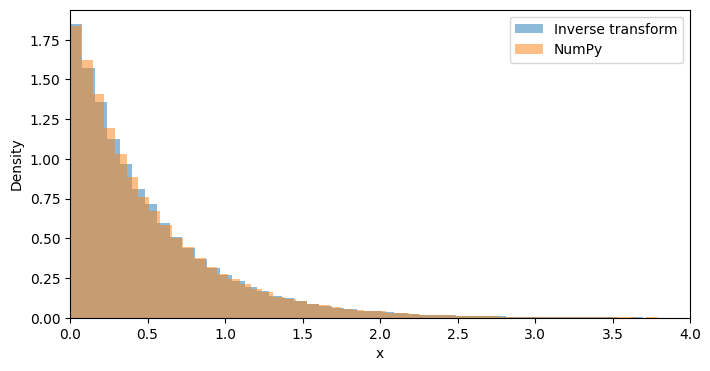

In [8]:
rng1 = np.random.default_rng(100)
rng2 = np.random.default_rng(200)

n = 200_000
lam = 2.0

u = rng1.random(n)
x_manual = -np.log(u) / lam

x_numpy = rng2.exponential(scale=1/lam, size=n)

print("Manual mean:", x_manual.mean())
print("NumPy mean :", x_numpy.mean())

plt.figure(figsize=(8, 4))
plt.hist(x_manual, bins=80, density=True, alpha=0.5, label="Inverse transform")
plt.hist(x_numpy, bins=80, density=True, alpha=0.5, label="NumPy")
plt.xlim(0, 4)
plt.legend()
plt.xlabel("x")
plt.ylabel("Density")
plt.show()


<div dir="rtl" align="right">

# 12. Inverse Transform להתפלגות כללית

### אם ל־CDF יש פונקציה הפוכה זמינה, אפשר להשתמש ישירות ברעיון $X=F^{-1}(U)$.

### בפועל, עבור חלק מההתפלגויות אין ביטוי אלגברי פשוט ל־$F^{-1}$ ולכן משתמשים בקירובים נומריים או באלגוריתמי דגימה אחרים.

</div>

<div dir="rtl" align="right">

# 13. דוגמה: Uniform כללי על קטע

### נניח שאנו רוצים $X\sim U(a,b)$.

### אם $U\sim U(0,1)$, אז הטרנספורמציה $X=a+(b-a)U$ נותנת בדיוק Uniform על הקטע $[a,b]$.

</div>

In [9]:
rng = np.random.default_rng(9)

a = 5
b = 12

u = rng.random(1_000_000)
x = a + (b - a) * u

print("Estimated mean:", x.mean())
print("Theoretical mean:", (a+b)/2)
print("Estimated min/max:", x.min(), x.max())


Estimated mean: 8.497497310826118
Theoretical mean: 8.5
Estimated min/max: 5.00003153367288 11.999982300023774


<div dir="rtl" align="right">

# 14. דוגמה: Normal

### עבור התפלגות נורמלית סטנדרטית ניתן עקרונית להשתמש ב־$X=\Phi^{-1}(U)$ כאשר $\Phi$ היא פונקציית ההתפלגות המצטברת של $N(0,1)$.

### מאחר שאין ל־$\Phi^{-1}$ נוסחה אלמנטרית פשוטה, בפועל משתמשים באלגוריתמים יעילים אחרים או בקירובים נומריים.

### דוגמה קלאסית היא שיטת Box–Muller שמשתמשת בשתי הגרלות Uniform בלתי תלויות.

</div>

<div dir="rtl" align="right">

# 15. שיטת Box–Muller

### נגריל $U_1,U_2\sim U(0,1)$ באופן בלתי תלוי.

### נגדיר $Z_1=\sqrt{-2\ln U_1}\cos(2\pi U_2)$.

### נגדיר גם $Z_2=\sqrt{-2\ln U_1}\sin(2\pi U_2)$.

### שני המשתנים $Z_1$ ו־$Z_2$ מתפלגים $N(0,1)$.

</div>

In [10]:
rng = np.random.default_rng(1234)

n = 500_000
u1 = rng.random(n)
u2 = rng.random(n)

z1 = np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
z2 = np.sqrt(-2 * np.log(u1)) * np.sin(2 * np.pi * u2)

print("Z1 mean:", z1.mean())
print("Z1 variance:", z1.var())
print("Z2 mean:", z2.mean())
print("Z2 variance:", z2.var())


Z1 mean: -0.0007317238842130777
Z1 variance: 1.0001377183847595
Z2 mean: -0.0005926774759961138
Z2 variance: 0.9970158273949048


In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(z1, bins=80, density=True, edgecolor="black")
plt.xlabel("z")
plt.ylabel("Density")
plt.title("Normal random variables generated by Box-Muller")
plt.show()


<div dir="rtl" align="right">

# 16. כיצד NumPy עובד רעיונית?

### כאשר אנו כותבים `rng.random()`, המחולל הפסאודו־אקראי מייצר ביטים פסאודו־אקראיים וממיר אותם למספר בתחום $[0,1)$.

### כאשר אנו כותבים `rng.exponential()`, `rng.normal()` או `rng.gamma()`, NumPy משתמש באותם ביטים פסאודו־אקראיים יחד עם אלגוריתם דגימה המתאים להתפלגות המבוקשת.

### לכן Uniform הוא דרך טובה להבין את עקרון הבנייה, אף שבמימושים מודרניים לא כל התפלגות נוצרת בפועל על ידי חישוב מפורש של Uniform ולאחר מכן inverse CDF.

</div>

In [11]:
rng = np.random.default_rng(2026)

print("Uniform:", rng.random(5))
print("Exponential:", rng.exponential(scale=2, size=5))
print("Normal:", rng.normal(loc=0, scale=1, size=5))
print("Gamma:", rng.gamma(shape=3, scale=2, size=5))
print("Weibull:", rng.weibull(a=2, size=5))


Uniform: [0.17893481 0.63991317 0.4672684  0.37050053 0.35491733]
Exponential: [2.13657625 2.56963924 0.03718689 1.82338882 1.2691516 ]
Normal: [ 0.72006782  0.51470521 -0.06412794 -0.08547656  0.16091632]
Gamma: [3.56880249 7.33181193 1.98606801 7.77812698 4.8621724 ]
Weibull: [1.09555323 0.89966853 1.37835321 0.63208941 1.61525891]


<div dir="rtl" align="right">

# 17. דוגמה מעולם התורים

### נניח שאנו רוצים לסמלץ תור $M/M/1$ עם קצב הגעה $\lambda$ וקצב שירות $\mu$.

### זמני הביניים בין הגעות מתפלגים $Exp(\lambda)$ וזמני השירות מתפלגים $Exp(\mu)$.

### ניתן לבנות את שתי סדרות הזמנים ישירות מהגרלות Uniform.

</div>

In [12]:
rng = np.random.default_rng(123)

lam = 2.0
mu = 3.0
n = 10

u_arrivals = rng.random(n)
u_service = rng.random(n)

interarrival_times = -np.log(u_arrivals) / lam
service_times = -np.log(u_service) / mu

print("Interarrival times:")
print(interarrival_times)

print("\nService times:")
print(service_times)


Interarrival times:
[0.19110491 1.4610456  0.75624664 0.84540042 0.86890304 0.10406928
 0.03987617 0.64263771 0.09937515 0.0583272 ]

Service times:
[0.22251234 0.46888052 0.06443053 0.51429584 0.09970818 0.15404346
 0.02512083 0.48713791 0.07474591 0.21915383]


<div dir="rtl" align="right">

# 18. שחזור סימולציה שלמה באמצעות seed

### אם כל ההגרלות בסימולציה נוצרות מאותו generator, קביעת seed קובעת למעשה את כל מסלול הסימולציה.

### לכן אותו seed ייצור את אותם זמני הגעה, אותם זמני שירות ובהתאם גם את אותם אורכי תור וזמני המתנה.

</div>

In [14]:
def generate_mm1_inputs(seed, lam=2.0, mu=3.0, n=5):
    rng = np.random.default_rng(seed)
    interarrival = rng.exponential(scale=1/lam, size=n)
    service = rng.exponential(scale=1/mu, size=n)
    return interarrival, service

a1, s1 = generate_mm1_inputs(55)
a2, s2 = generate_mm1_inputs(55)


print(a1)
print(s1)


[0.75409342 3.35073077 0.14145016 0.13270226 0.56825274]
[0.12463028 0.2911874  0.49630754 0.04216288 0.54332278]


<div dir="rtl" align="right">

# 19. סיכום

### מחשב מייצר בדרך כלל מספרים פסאודו־אקראיים באמצעות אלגוריתם דטרמיניסטי שמתחיל ממצב התחלתי הנקבע על ידי seed.

### PRNG טוב יוצר סדרות בעלות תכונות סטטיסטיות הדומות מאוד לאלו של מספרים אקראיים אמיתיים.

### מספרים אחידים על $[0,1]$ הם אבן בניין מרכזית משום שניתן למפות אותם להתפלגויות שונות באמצעות חלוקת הקטע, inverse transform או אלגוריתמי דגימה אחרים.

### בסימולציה, בחירת seed מאפשרת reproducibility ולכן היא כלי חשוב במיוחד בניסויים מחקריים ובהשוואה בין מערכות.

</div>